# TACS (Ours) - ISIC 2017 Segmentation

Notebook này thử nghiệm TACS cho bài toán segmentation trên ISIC 2017.

Mục tiêu benchmark theo Table 3 của paper:

| Method | ISIC 2017 Dice | ISIC 2017 IoU |
|---|---:|---:|
| No-Context | 83.3 | 74.4 |
| Random Context Ret. | 83.7 | 76.3 |
| Frozen DINO Similarity Ret. | 84.4 | 76.0 |
| Feature-Averaged Context | 84.5 | 75.6 |
| TACS (Ours) | 85.0 | 76.5 |

Thiết kế chính:

- Dùng standard split sẵn có: `train/images`, `train/masks`, `val/images`, `val/masks`, `test/images`, `test/masks`.
- Candidate pool lấy 20% train split, cố định bằng seed; khi train sẽ loại chính query khỏi candidate scores nếu query nằm trong pool.
- Selector score query với toàn bộ candidate pool.
- Dùng straight-through Gumbel-Softmax (`tau=0.1`) trong training.
- Reward: `loss_query_only - loss_with_context`.
- Backbone DINOv3 ViT-S/16 frozen, đúng hướng segmentation trong paper.

Lưu ý fidelity: paper nói chèn gated cross-attention vào từng transformer block và dùng lightweight DPT head. Notebook này dùng biến thể thực nghiệm gọn hơn: lấy patch tokens cuối của DINOv3 frozen, áp dụng trainable gated cross-attention trên tokens đó, rồi giải mã bằng DPT-lite head. Cơ chế selector/reward/candidate pool vẫn giữ tinh thần TACS.

## 1. Cài thư viện

Kaggle thường đã có PyTorch/torchvision. Cell này chỉ cài các thư viện nhẹ nếu thiếu.

In [1]:
%pip -q install pandas pillow tqdm matplotlib

Note: you may need to restart the kernel to use updated packages.


## 2. Import, seed và cấu hình

`DATASET_ROOT` sẽ tự dò thư mục có cấu trúc:

```text
DATASET_ROOT/
├── train/
│   ├── images/
│   └── masks/
├── val/
│   ├── images/
│   └── masks/
└── test/
    ├── images/
    └── masks/
```

In [2]:
import json
import math
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.transforms import InterpolationMode
import torchvision.transforms.functional as TF
from tqdm.auto import tqdm

torch.backends.cudnn.benchmark = True
torch.set_float32_matmul_precision("high")
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

PROJECT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
OUT_PUT_DIR = PROJECT_DIR / "outputs" / "tacs_isic2017_segmentation"
OUTPUT_DIR = OUT_PUT_DIR
OUT_PUT_DIR.mkdir(parents=True, exist_ok=True)

# DINOv3 repo/weights: chỉnh lại nếu Kaggle input của bạn đặt khác.
DINOV3_REPO_DIR = "/kaggle/input/datasets/nguyenducxu/dinov3-code/dinov3-main"
if not Path(DINOV3_REPO_DIR).exists():
    for p in [
        Path("/kaggle/input/dinov3-code/dinov3-main"),
        Path("/kaggle/input/dinov3-code"),
        Path("./dinov3-main"),
    ]:
        if p.exists():
            DINOV3_REPO_DIR = str(p)
            break

DINOV3_MODEL_NAME = "dinov3_vits16"
DINOV3_WEIGHTS = "/kaggle/input/datasets/nguyenducxu/dinov3/dinov3_vits16_pretrain_lvd1689m-08c60483.pth"
if not Path(DINOV3_WEIGHTS).exists():
    for p in [
        Path("/kaggle/input/dinov3/dinov3_vits16_pretrain_lvd1689m-08c60483.pth"),
        Path("/kaggle/input/dinov3/dinov3_vits16.pth"),
        Path("./dinov3_vits16_pretrain_lvd1689m-08c60483.pth"),
    ]:
        if p.exists():
            DINOV3_WEIGHTS = str(p)
            break

BACKBONE_NAME = DINOV3_MODEL_NAME
FEATURE_DIM = 384
PATCH_SIZE = 16
IMAGE_SIZE = 448

EPOCHS = 100
BATCH_SIZE = 8
NUM_WORKERS = 4
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
WARMUP_EPOCHS = 5
PATIENCE = 15
GRAD_CLIP_NORM = 1.0

CANDIDATE_POOL_FRACTION = 0.20
CANDIDATE_FEATURE_BATCH_SIZE = 64
TACS_GUMBEL_TAU = 0.10
TACS_POLICY_WEIGHT = 1.0
TACS_ENTROPY_WEIGHT = 0.01
TACS_SELECTOR_DROPOUT = 0.10
TACS_SELECTOR_TEMPERATURE = 1.0
NUM_CROSS_ATTENTION_LAYERS = 2
CROSS_ATTENTION_HEADS = 6
DECODER_DROPOUT = 0.10

DICE_LOSS_WEIGHT = 1.0
BCE_LOSS_WEIGHT = 1.0
THRESHOLD = 0.5

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

print("OUT_PUT_DIR:", OUT_PUT_DIR.resolve())

DEVICE: cuda
OUT_PUT_DIR: /kaggle/working/outputs/tacs_isic2017_segmentation


## 3. Đọc dataset ISIC 2017 segmentation

Cell này tự ghép ảnh và mask theo stem file. Với ISIC, mask thường có hậu tố `_segmentation`, nên notebook đã xử lý trường hợp đó.

In [3]:
def find_isic_dataset_root():
    manual_candidates = [
        Path("/kaggle/input/datasets/arnabpurk/isic-2017-segmentation-dataset-original/ISIC-2017 Segmentation Dataset - Original"),
        Path("/kaggle/input/isic-2017-segmentation-dataset"),
        Path("/kaggle/input/ISIC-2017 Segmentation Dataset"),
        Path("./ISIC-2017 Segmentation Dataset"),
    ]
    for root in manual_candidates:
        if (root / "train" / "images").is_dir() and (root / "train" / "masks").is_dir():
            return root

    input_root = Path("/kaggle/input")
    if input_root.exists():
        for root in input_root.rglob("*"):
            if not root.is_dir():
                continue
            if (root / "train" / "images").is_dir() and (root / "train" / "masks").is_dir():
                return root

    raise FileNotFoundError(
        "Khong tim thay DATASET_ROOT co train/images va train/masks. "
        "Hay sua DATASET_ROOT thu cong trong cell nay."
    )


DATASET_ROOT = find_isic_dataset_root()
print("DATASET_ROOT:", DATASET_ROOT)

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}


def normalize_mask_stem(stem):
    for suffix in ["_segmentation", "_mask", "_lesion", "_Segmentation", "_Mask"]:
        if stem.endswith(suffix):
            return stem[: -len(suffix)]
    return stem


def list_split_pairs(dataset_root, split):
    image_dir = dataset_root / split / "images"
    mask_dir = dataset_root / split / "masks"
    if not image_dir.is_dir() or not mask_dir.is_dir():
        raise FileNotFoundError(f"Thieu {split}/images hoac {split}/masks trong {dataset_root}")

    image_paths = sorted([p for p in image_dir.rglob("*") if p.suffix.lower() in IMAGE_EXTS])
    mask_paths = sorted([p for p in mask_dir.rglob("*") if p.suffix.lower() in IMAGE_EXTS])
    mask_index = {normalize_mask_stem(p.stem): p for p in mask_paths}

    rows = []
    missing = []
    for image_path in image_paths:
        key = image_path.stem
        mask_path = mask_index.get(key)
        if mask_path is None:
            missing.append(image_path.name)
            continue
        rows.append({
            "split": split,
            "fname": image_path.name,
            "image_id": image_path.stem,
            "image_path": str(image_path),
            "mask_path": str(mask_path),
        })

    if missing:
        raise FileNotFoundError(f"Khong tim thay mask cho {len(missing)} anh, vi du: {missing[:5]}")
    if not rows:
        raise RuntimeError(f"Khong doc duoc cap image/mask nao trong split {split}")

    df = pd.DataFrame(rows).reset_index(drop=True)
    df["row_id"] = np.arange(len(df))
    return df


train_df = list_split_pairs(DATASET_ROOT, "train")
val_df = list_split_pairs(DATASET_ROOT, "val")
test_df = list_split_pairs(DATASET_ROOT, "test")

candidate_rng = np.random.default_rng(SEED)
candidate_pool_size = max(1, int(round(len(train_df) * CANDIDATE_POOL_FRACTION)))
candidate_pool_positions = np.sort(candidate_rng.choice(len(train_df), size=candidate_pool_size, replace=False))
candidate_df = train_df.iloc[candidate_pool_positions].reset_index(drop=True)

train_df.to_csv(OUT_PUT_DIR / "train_split.csv", index=False)
val_df.to_csv(OUT_PUT_DIR / "val_split.csv", index=False)
test_df.to_csv(OUT_PUT_DIR / "test_split.csv", index=False)
candidate_df.to_csv(OUT_PUT_DIR / "candidate_pool.csv", index=False)

print(f"Train images: {len(train_df):,}")
print(f"Val images: {len(val_df):,}")
print(f"Test images: {len(test_df):,}")
print(f"Candidate pool: {len(candidate_df):,}/{len(train_df):,} train images ({CANDIDATE_POOL_FRACTION:.0%})")
display(train_df.head())
display(candidate_df.head())

DATASET_ROOT: /kaggle/input/datasets/arnabpurk/isic-2017-segmentation-dataset-original/ISIC-2017 Segmentation Dataset - Original
Train images: 2,000
Val images: 150
Test images: 600
Candidate pool: 400/2,000 train images (20%)


,split,fname,image_id,image_path,mask_path,row_id
0,train,ISIC_0000000.jpg,ISIC_0000000,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,0
1,train,ISIC_0000001.jpg,ISIC_0000001,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,1
2,train,ISIC_0000002.jpg,ISIC_0000002,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,2
3,train,ISIC_0000003.jpg,ISIC_0000003,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,3
4,train,ISIC_0000004.jpg,ISIC_0000004,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,4


,split,fname,image_id,image_path,mask_path,row_id
0,train,ISIC_0000011.jpg,ISIC_0000011,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,10
1,train,ISIC_0000013.jpg,ISIC_0000013,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,12
2,train,ISIC_0000019.jpg,ISIC_0000019,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,18
3,train,ISIC_0000037.jpg,ISIC_0000037,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,35
4,train,ISIC_0000042.jpg,ISIC_0000042,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,/kaggle/input/datasets/arnabpurk/isic-2017-seg...,40


## 4. Transform và Dataset

Train transform dùng joint augmentation cho image/mask: random resized crop, horizontal flip, vertical flip. Eval/candidate transform deterministic.

In [4]:
class JointTrainTransform:
    def __init__(self, image_size=256):
        self.image_size = int(image_size)
        self.color_jitter = transforms.ColorJitter(
            brightness=0.15,
            contrast=0.15,
            saturation=0.10,
            hue=0.02,
        )

    def __call__(self, image, mask):
        image = image.convert("RGB")
        mask = mask.convert("L")

        i, j, h, w = transforms.RandomResizedCrop.get_params(
            image,
            scale=(0.75, 1.00),
            ratio=(0.90, 1.10),
        )
        image = TF.resized_crop(
            image, i, j, h, w, (self.image_size, self.image_size), InterpolationMode.BILINEAR
        )
        mask = TF.resized_crop(
            mask, i, j, h, w, (self.image_size, self.image_size), InterpolationMode.NEAREST
        )

        if random.random() < 0.5:
            image = TF.hflip(image)
            mask = TF.hflip(mask)
        if random.random() < 0.5:
            image = TF.vflip(image)
            mask = TF.vflip(mask)
        if random.random() < 0.5:
            image = self.color_jitter(image)

        image = TF.to_tensor(image)
        image = TF.normalize(image, IMAGENET_MEAN, IMAGENET_STD)
        mask = TF.to_tensor(mask)
        mask = (mask > 0.5).float()
        return image, mask


class JointEvalTransform:
    def __init__(self, image_size=256):
        self.image_size = int(image_size)

    def __call__(self, image, mask=None):
        image = image.convert("RGB")
        image = TF.resize(image, (self.image_size, self.image_size), InterpolationMode.BILINEAR)
        image = TF.to_tensor(image)
        image = TF.normalize(image, IMAGENET_MEAN, IMAGENET_STD)
        if mask is None:
            return image
        mask = mask.convert("L")
        mask = TF.resize(mask, (self.image_size, self.image_size), InterpolationMode.NEAREST)
        mask = TF.to_tensor(mask)
        mask = (mask > 0.5).float()
        return image, mask


train_transform = JointTrainTransform(IMAGE_SIZE)
eval_transform = JointEvalTransform(IMAGE_SIZE)


class ISICSegmentationDataset(Dataset):
    def __init__(self, annotations, transform, return_mask=True):
        self.annotations = annotations.reset_index(drop=True).copy()
        self.transform = transform
        self.return_mask = bool(return_mask)

    def __len__(self):
        return len(self.annotations)

    def __getitem__(self, index):
        row = self.annotations.iloc[index]
        image = Image.open(row["image_path"]).convert("RGB")
        if self.return_mask:
            mask = Image.open(row["mask_path"]).convert("L")
            image, mask = self.transform(image, mask)
        else:
            image = self.transform(image, None)
            mask = torch.empty(0)
        return {
            "image": image,
            "mask": mask,
            "fname": row["fname"],
            "image_id": row["image_id"],
            "row_id": int(row["row_id"]),
        }


sample = ISICSegmentationDataset(train_df.head(2), train_transform)[0]
print("Sample image:", sample["image"].shape, sample["image"].dtype)
print("Sample mask:", sample["mask"].shape, sample["mask"].min().item(), sample["mask"].max().item())

Sample image: torch.Size([3, 448, 448]) torch.float32
Sample mask: torch.Size([1, 448, 448]) 0.0 1.0


## 5. Load DINOv3 frozen backbone

Backbone được freeze cho segmentation, đúng mô tả implementation details của paper.

In [5]:
def resolve_dinov3_weights():
    path = Path(DINOV3_WEIGHTS)
    if not path.is_file():
        raise FileNotFoundError(f"Khong tim thay DINOv3 weights: {path}")
    return str(path)


def load_dinov3_model(repo_dir, model_name, weights_path):
    repo_dir = Path(repo_dir)
    if not repo_dir.is_dir():
        raise FileNotFoundError(f"Khong tim thay DINOV3_REPO_DIR: {repo_dir}")
    weights_path = Path(weights_path)
    if not weights_path.is_file():
        raise FileNotFoundError(f"Khong tim thay DINOV3_WEIGHTS: {weights_path}")
    return torch.hub.load(str(repo_dir), model_name, source="local", weights=str(weights_path))


def ensure_dinov3_assets():
    resolve_dinov3_weights()
    if not Path(DINOV3_REPO_DIR).is_dir():
        raise FileNotFoundError(f"Khong tim thay DINOv3 repo: {DINOV3_REPO_DIR}")
    print("DINOv3 repo:", DINOV3_REPO_DIR)
    print("DINOv3 weights:", DINOV3_WEIGHTS)


ensure_dinov3_assets()

DINOv3 repo: /kaggle/input/datasets/nguyenducxu/dinov3-code/dinov3-main
DINOv3 weights: /kaggle/input/datasets/nguyenducxu/dinov3/dinov3_vits16_pretrain_lvd1689m-08c60483.pth


## 6. Model: TACS selector + gated cross-attention segmentation

Selector học score giữa query feature và candidate feature. Downstream segmentation dùng context tokens được chọn để tăng cường query tokens bằng gated cross-attention rồi decode mask.

In [6]:
class FrozenDinoV3FeatureExtractor(nn.Module):
    def __init__(self, repo_dir, model_name, weights_path):
        super().__init__()
        self.backbone = load_dinov3_model(repo_dir, model_name, weights_path)
        for p in self.backbone.parameters():
            p.requires_grad_(False)
        self.backbone.eval()

    def forward_features(self, images):
        with torch.no_grad():
            with torch.amp.autocast("cuda", enabled=DEVICE.type == "cuda"):
                features = self.backbone.forward_features(images)
        if isinstance(features, dict):
            if "x_norm_patchtokens" in features:
                patch_tokens = features["x_norm_patchtokens"]
            elif "x_norm_patch_tokens" in features:
                patch_tokens = features["x_norm_patch_tokens"]
            else:
                tensor_values = [v for v in features.values() if torch.is_tensor(v) and v.ndim == 3]
                if not tensor_values:
                    raise KeyError(f"Khong tim thay patch tokens trong keys: {list(features)}")
                patch_tokens = tensor_values[0]

            if "x_norm_clstoken" in features:
                global_features = features["x_norm_clstoken"]
            elif "x_norm_cls_token" in features:
                global_features = features["x_norm_cls_token"]
            else:
                global_features = patch_tokens.mean(dim=1)
            return patch_tokens.float(), global_features.float()

        if torch.is_tensor(features):
            if features.ndim == 3:
                return features[:, 1:].float(), features[:, 0].float()
            if features.ndim == 2:
                raise RuntimeError("Backbone chi tra ve global feature, khong co patch tokens.")
        raise TypeError(f"Output DINO khong ho tro: {type(features)}")


class TACSSelector(nn.Module):
    def __init__(self, feature_dim=384, hidden_dim=384, dropout=0.1, temperature=1.0):
        super().__init__()
        self.temperature = float(temperature)
        self.query_proj = nn.Sequential(
            nn.LayerNorm(feature_dim),
            nn.Linear(feature_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, feature_dim),
        )
        self.candidate_proj = nn.Sequential(
            nn.LayerNorm(feature_dim),
            nn.Linear(feature_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, feature_dim),
        )
        self.logit_scale = nn.Parameter(torch.tensor(1.0))

    def score(self, query_features, candidate_features):
        q = F.normalize(self.query_proj(query_features.float()), dim=-1)
        c = F.normalize(self.candidate_proj(candidate_features.float()), dim=-1)
        scores = q @ c.T
        return scores * self.logit_scale.clamp(0.01, 100.0) / max(self.temperature, 1e-6)


class GatedCrossAttentionBlock(nn.Module):
    def __init__(self, feature_dim=384, num_heads=6, dropout=0.1):
        super().__init__()
        self.query_norm = nn.LayerNorm(feature_dim)
        self.context_norm = nn.LayerNorm(feature_dim)
        self.attn = nn.MultiheadAttention(
            embed_dim=feature_dim,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True,
        )
        self.gate = nn.Sequential(
            nn.LayerNorm(feature_dim * 2),
            nn.Linear(feature_dim * 2, feature_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(feature_dim, feature_dim),
            nn.Sigmoid(),
        )
        self.ffn = nn.Sequential(
            nn.LayerNorm(feature_dim),
            nn.Linear(feature_dim, feature_dim * 4),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(feature_dim * 4, feature_dim),
        )

    def forward(self, query_tokens, context_tokens):
        q = self.query_norm(query_tokens)
        c = self.context_norm(context_tokens)
        attn_out, _ = self.attn(q, c, c, need_weights=False)
        gate_input = torch.cat([query_tokens, attn_out], dim=-1)
        gate = self.gate(gate_input)
        x = query_tokens + gate * attn_out
        x = x + self.ffn(x)
        return x


class DPTLiteHead(nn.Module):
    def __init__(self, feature_dim=384, out_channels=1, dropout=0.1):
        super().__init__()
        self.proj = nn.Sequential(
            nn.LayerNorm(feature_dim),
        )
        self.decoder = nn.Sequential(
            nn.Conv2d(feature_dim, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.GELU(),
            nn.Dropout2d(dropout),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),

            nn.Conv2d(256, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.GELU(),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),

            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.GELU(),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),

            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.GELU(),
            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),

            nn.Conv2d(32, out_channels, kernel_size=1),
        )

    def forward(self, tokens, image_size=256):
        b, n, d = tokens.shape
        grid = int(math.sqrt(n))
        if grid * grid != n:
            raise RuntimeError(f"So patch tokens {n} khong tao duoc grid vuong.")
        x = self.proj(tokens)
        x = x.transpose(1, 2).reshape(b, d, grid, grid)
        logits = self.decoder(x)
        if logits.shape[-2:] != (image_size, image_size):
            logits = F.interpolate(logits, size=(image_size, image_size), mode="bilinear", align_corners=False)
        return logits


class TACSSegmentationModel(nn.Module):
    def __init__(self, repo_dir, model_name, weights_path, feature_dim=384):
        super().__init__()
        self.feature_extractor = FrozenDinoV3FeatureExtractor(repo_dir, model_name, weights_path)
        self.selector = TACSSelector(
            feature_dim=feature_dim,
            hidden_dim=feature_dim,
            dropout=TACS_SELECTOR_DROPOUT,
            temperature=TACS_SELECTOR_TEMPERATURE,
        )
        self.cross_attention = nn.ModuleList([
            GatedCrossAttentionBlock(
                feature_dim=feature_dim,
                num_heads=CROSS_ATTENTION_HEADS,
                dropout=DECODER_DROPOUT,
            )
            for _ in range(NUM_CROSS_ATTENTION_LAYERS)
        ])
        self.decoder = DPTLiteHead(feature_dim=feature_dim, dropout=DECODER_DROPOUT)

    def encode_images(self, images):
        return self.feature_extractor.forward_features(images)

    def select_context(self, query_global, candidate_global_bank, use_gumbel=True, forbidden_indices=None):
        selector_scores = self.selector.score(query_global, candidate_global_bank)
        if forbidden_indices is not None:
            valid = forbidden_indices >= 0
            if torch.any(valid):
                selector_scores = selector_scores.clone()
                rows = torch.arange(selector_scores.size(0), device=selector_scores.device)[valid]
                selector_scores[rows, forbidden_indices[valid]] = -1e4
        if self.training and use_gumbel:
            selection_weights = F.gumbel_softmax(
                selector_scores,
                tau=TACS_GUMBEL_TAU,
                hard=True,
                dim=1,
            )
            selected_indices = selection_weights.argmax(dim=1)
        else:
            selected_indices = selector_scores.argmax(dim=1)
            selection_weights = F.one_hot(selected_indices, num_classes=selector_scores.size(1)).to(selector_scores.dtype)
        entropy = torch.distributions.Categorical(logits=selector_scores.float()).entropy().mean()
        return {
            "selector_scores": selector_scores,
            "selection_weights": selection_weights,
            "selected_indices": selected_indices,
            "selector_entropy": entropy,
        }

    def decode_with_context_tokens(self, query_tokens, context_tokens):
        x = query_tokens
        for block in self.cross_attention:
            x = block(x, context_tokens)
        return self.decoder(x, image_size=IMAGE_SIZE)

    def forward_query_only_from_tokens(self, query_tokens):
        return self.decoder(query_tokens, image_size=IMAGE_SIZE)

    def forward_with_context(self, images, context_tokens):
        query_tokens, query_global = self.encode_images(images)
        logits = self.decode_with_context_tokens(query_tokens, context_tokens)
        return logits, query_tokens, query_global


model = TACSSegmentationModel(
    DINOV3_REPO_DIR,
    DINOV3_MODEL_NAME,
    resolve_dinov3_weights(),
    feature_dim=FEATURE_DIM,
).to(DEVICE)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Total params: {total_params:,}")
print(f"Trainable params: {trainable_params:,}")
print(model.__class__.__name__)

Total params: 27,907,906
Trainable params: 6,306,754
TACSSegmentationModel


## 7. Build candidate feature/token bank

Vì segmentation dùng frozen DINO backbone, candidate bank chỉ cần encode một lần. Khi train/test, selector vẫn score query với toàn bộ candidate pool.

In [7]:
@torch.no_grad()
def build_candidate_banks(network, annotations):
    dataset = ISICSegmentationDataset(annotations, eval_transform, return_mask=False)
    loader = DataLoader(
        dataset,
        batch_size=CANDIDATE_FEATURE_BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=NUM_WORKERS > 0,
    )
    patch_banks = []
    global_banks = []
    fnames = []
    image_ids = []
    network.eval()
    for batch in tqdm(loader, desc="encode candidate pool", leave=False):
        images = batch["image"].to(DEVICE, non_blocking=True)
        patch_tokens, global_features = network.encode_images(images)
        patch_banks.append(patch_tokens.detach().cpu().half())
        global_banks.append(global_features.detach().cpu().float())
        fnames.extend(batch["fname"])
        image_ids.extend(batch["image_id"])

    candidate_patch_bank = torch.cat(patch_banks, dim=0).to(DEVICE, non_blocking=True)
    candidate_global_bank = torch.cat(global_banks, dim=0).to(DEVICE, non_blocking=True)
    return candidate_patch_bank, candidate_global_bank, fnames, image_ids


candidate_patch_bank, candidate_global_bank, candidate_fnames, candidate_image_ids = build_candidate_banks(model, candidate_df)
torch.save({
    "candidate_patch_bank": candidate_patch_bank.detach().cpu(),
    "candidate_global_bank": candidate_global_bank.detach().cpu(),
    "candidate_fnames": candidate_fnames,
    "candidate_image_ids": candidate_image_ids,
    "candidate_pool_positions": candidate_pool_positions,
    "seed": SEED,
}, OUT_PUT_DIR / "candidate_banks.pt")

print("candidate_patch_bank:", tuple(candidate_patch_bank.shape), candidate_patch_bank.dtype, candidate_patch_bank.device)
print("candidate_global_bank:", tuple(candidate_global_bank.shape), candidate_global_bank.dtype, candidate_global_bank.device)

encode candidate pool:   0%|          | 0/7 [00:00<?, ?it/s]

candidate_patch_bank: (400, 784, 384) torch.float16 cuda:0
candidate_global_bank: (400, 384) torch.float32 cuda:0


## 8. Loss, metrics và dataloaders

In [8]:
def segmentation_loss_per_sample(logits, masks):
    bce = F.binary_cross_entropy_with_logits(logits, masks, reduction="none").mean(dim=(1, 2, 3))
    probs = torch.sigmoid(logits)
    dims = (1, 2, 3)
    intersection = (probs * masks).sum(dim=dims)
    union = probs.sum(dim=dims) + masks.sum(dim=dims)
    dice_loss = 1.0 - (2.0 * intersection + 1e-6) / (union + 1e-6)
    return BCE_LOSS_WEIGHT * bce + DICE_LOSS_WEIGHT * dice_loss


def dice_iou_from_logits(logits, masks, threshold=0.5):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    dims = (1, 2, 3)
    intersection = (preds * masks).sum(dim=dims)
    pred_sum = preds.sum(dim=dims)
    mask_sum = masks.sum(dim=dims)
    dice = (2.0 * intersection + 1e-6) / (pred_sum + mask_sum + 1e-6)
    iou = (intersection + 1e-6) / (pred_sum + mask_sum - intersection + 1e-6)
    return dice, iou


def soft_dice_iou_from_logits(logits, masks):
    probs = torch.sigmoid(logits)
    dims = (1, 2, 3)
    intersection = (probs * masks).sum(dim=dims)
    pred_sum = probs.sum(dim=dims)
    mask_sum = masks.sum(dim=dims)
    dice = (2.0 * intersection + 1e-6) / (pred_sum + mask_sum + 1e-6)
    iou = (intersection + 1e-6) / (pred_sum + mask_sum - intersection + 1e-6)
    return dice, iou


candidate_row_id_to_pool_pos = {
    int(row_id): int(pos)
    for pos, row_id in enumerate(candidate_df["row_id"].tolist())
}


def forbidden_pool_indices_from_row_ids(row_ids):
    values = [
        candidate_row_id_to_pool_pos.get(int(row_id), -1)
        for row_id in row_ids.detach().cpu().tolist()
    ]
    return torch.tensor(values, dtype=torch.long, device=DEVICE)


def select_candidate_tokens_from_weights(selection_weights):
    flat_bank = candidate_patch_bank.flatten(1)
    weights = selection_weights.to(device=flat_bank.device, dtype=flat_bank.dtype)
    selected_flat = weights @ flat_bank
    return selected_flat.view(weights.size(0), *candidate_patch_bank.shape[1:]).float()


def gather_candidate_tokens(indices):
    return candidate_patch_bank[indices.detach().to(candidate_patch_bank.device)].float()


train_dataset = ISICSegmentationDataset(train_df, train_transform, return_mask=True)
val_dataset = ISICSegmentationDataset(val_df, eval_transform, return_mask=True)
test_dataset = ISICSegmentationDataset(test_df, eval_transform, return_mask=True)

loader_kwargs = {
    "num_workers": NUM_WORKERS,
    "pin_memory": torch.cuda.is_available(),
}
if NUM_WORKERS > 0:
    loader_kwargs["persistent_workers"] = True
    loader_kwargs["prefetch_factor"] = 2

train_generator = torch.Generator()
train_generator.manual_seed(SEED)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=train_generator, **loader_kwargs)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

warmup_epochs = max(1, min(WARMUP_EPOCHS, EPOCHS))
main_epochs = max(1, EPOCHS - warmup_epochs)
warmup_scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer,
    start_factor=0.2,
    end_factor=1.0,
    total_iters=warmup_epochs,
)
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=main_epochs,
    eta_min=1e-7,
)
scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer,
    schedulers=[warmup_scheduler, cosine_scheduler],
    milestones=[warmup_epochs],
)
scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")

checkpoint_path = OUT_PUT_DIR / "final_tacs_isic2017_segmentation.pt"
last_checkpoint_path = OUT_PUT_DIR / "checkpoint_last.pt"
best_checkpoint_path = OUT_PUT_DIR / "best_val_checkpoint.pt"

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 250
Val batches: 19
Test batches: 75


## 9. Train TACS segmentation

Mỗi batch:

1. Encode query bằng DINOv3 frozen.
2. Selector score query với toàn bộ candidate pool.
3. Chọn context bằng straight-through Gumbel-Softmax.
4. Decode mask từ query tokens + selected context tokens.
5. Policy reward so sánh query-only loss và with-context loss.
6. Lưu checkpoint sau từng epoch.

In [9]:
def move_batch_to_device(batch):
    return {
        "images": batch["image"].to(DEVICE, non_blocking=True),
        "masks": batch["mask"].to(DEVICE, non_blocking=True),
        "fname": batch["fname"],
        "image_id": batch["image_id"],
        "row_id": batch["row_id"].to(DEVICE, non_blocking=True),
    }


def train_one_epoch(epoch):
    model.train()
    model.feature_extractor.eval()
    running = {
        "loss": 0.0,
        "grad_loss": 0.0,
        "policy_loss": 0.0,
        "reward": 0.0,
        "entropy": 0.0,
        "dice": 0.0,
        "iou": 0.0,
        "soft_dice": 0.0,
        "soft_iou": 0.0,
        "total": 0,
    }
    progress = tqdm(train_loader, desc=f"Epoch {epoch:03d} [train]", leave=False)

    for batch in progress:
        moved = move_batch_to_device(batch)
        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda", enabled=DEVICE.type == "cuda"):
            query_tokens, query_global = model.encode_images(moved["images"])
            forbidden_indices = forbidden_pool_indices_from_row_ids(moved["row_id"])
            details = model.select_context(
                query_global,
                candidate_global_bank,
                use_gumbel=True,
                forbidden_indices=forbidden_indices,
            )
            context_tokens = select_candidate_tokens_from_weights(details["selection_weights"])
            logits = model.decode_with_context_tokens(query_tokens, context_tokens)

            grad_losses = segmentation_loss_per_sample(logits, moved["masks"])
            grad_loss = grad_losses.mean()

            selector_scores = details["selector_scores"].float()
            policy_dist = torch.distributions.Categorical(logits=selector_scores)
            policy_actions = policy_dist.sample()
            log_probs = policy_dist.log_prob(policy_actions)
            entropy = policy_dist.entropy().mean()

            with torch.no_grad():
                query_only_logits = model.forward_query_only_from_tokens(query_tokens)
                policy_context_tokens = gather_candidate_tokens(policy_actions)
                policy_logits = model.decode_with_context_tokens(query_tokens, policy_context_tokens)
                query_only_losses = segmentation_loss_per_sample(query_only_logits.float(), moved["masks"])
                policy_context_losses = segmentation_loss_per_sample(policy_logits.float(), moved["masks"])
                rewards = (query_only_losses - policy_context_losses).detach()
                reward_std = rewards.std(unbiased=False).clamp_min(1e-6)
                advantages = ((rewards - rewards.mean()) / reward_std).detach()

            policy_loss = -(log_probs * advantages).mean()
            loss = grad_loss + TACS_POLICY_WEIGHT * policy_loss - TACS_ENTROPY_WEIGHT * entropy

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], GRAD_CLIP_NORM)
        scaler.step(optimizer)
        scaler.update()

        with torch.no_grad():
            dice, iou = dice_iou_from_logits(logits.float(), moved["masks"], threshold=THRESHOLD)
            soft_dice, soft_iou = soft_dice_iou_from_logits(logits.float(), moved["masks"])

        batch_size = moved["images"].size(0)
        running["loss"] += loss.item() * batch_size
        running["grad_loss"] += grad_loss.item() * batch_size
        running["policy_loss"] += policy_loss.item() * batch_size
        running["reward"] += rewards.mean().item() * batch_size
        running["entropy"] += entropy.item() * batch_size
        running["dice"] += dice.mean().item() * batch_size
        running["iou"] += iou.mean().item() * batch_size
        running["soft_dice"] += soft_dice.mean().item() * batch_size
        running["soft_iou"] += soft_iou.mean().item() * batch_size
        running["total"] += batch_size
        progress.set_postfix(
            loss=running["loss"] / max(running["total"], 1),
            dice=running["dice"] / max(running["total"], 1),
            iou=running["iou"] / max(running["total"], 1),
        )

    total = max(running.pop("total"), 1)
    return {k: v / total for k, v in running.items()}


@torch.no_grad()
def evaluate(loader, desc="val"):
    model.eval()
    running = {
        "loss": 0.0,
        "dice": 0.0,
        "iou": 0.0,
        "soft_dice": 0.0,
        "soft_iou": 0.0,
        "entropy": 0.0,
        "mean_top1_score": 0.0,
        "total": 0,
    }
    for batch in tqdm(loader, desc=desc, leave=False):
        moved = move_batch_to_device(batch)
        with torch.amp.autocast("cuda", enabled=DEVICE.type == "cuda"):
            query_tokens, query_global = model.encode_images(moved["images"])
            details = model.select_context(query_global, candidate_global_bank, use_gumbel=False)
            context_tokens = gather_candidate_tokens(details["selected_indices"])
            logits = model.decode_with_context_tokens(query_tokens, context_tokens)
            losses = segmentation_loss_per_sample(logits, moved["masks"])

        dice, iou = dice_iou_from_logits(logits.float(), moved["masks"], threshold=THRESHOLD)
        soft_dice, soft_iou = soft_dice_iou_from_logits(logits.float(), moved["masks"])
        selected_scores = details["selector_scores"].gather(1, details["selected_indices"].view(-1, 1)).squeeze(1)

        batch_size = moved["images"].size(0)
        running["loss"] += losses.mean().item() * batch_size
        running["dice"] += dice.mean().item() * batch_size
        running["iou"] += iou.mean().item() * batch_size
        running["soft_dice"] += soft_dice.mean().item() * batch_size
        running["soft_iou"] += soft_iou.mean().item() * batch_size
        running["entropy"] += details["selector_entropy"].item() * batch_size
        running["mean_top1_score"] += selected_scores.float().mean().item() * batch_size
        running["total"] += batch_size

    total = max(running.pop("total"), 1)
    return {k: v / total for k, v in running.items()}


history = []
best_val_dice = -1.0
best_epoch = 0
bad_epochs = 0

for epoch in range(1, EPOCHS + 1):
    train_metrics = train_one_epoch(epoch)
    val_metrics = evaluate(val_loader, desc=f"Epoch {epoch:03d} [val]")
    scheduler.step()

    row = {
        "epoch": epoch,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"val_{k}": v for k, v in val_metrics.items()},
        "lr": optimizer.param_groups[0]["lr"],
    }
    history.append(row)
    history_df = pd.DataFrame(history)
    history_df.to_csv(OUT_PUT_DIR / "training_history.csv", index=False)

    ckpt = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "history": history,
        "config": {
            "image_size": IMAGE_SIZE,
            "batch_size": BATCH_SIZE,
            "candidate_pool_fraction": CANDIDATE_POOL_FRACTION,
            "tacs_gumbel_tau": TACS_GUMBEL_TAU,
            "tacs_policy_weight": TACS_POLICY_WEIGHT,
            "num_cross_attention_layers": NUM_CROSS_ATTENTION_LAYERS,
            "paper_target_isic2017_dice": 0.850,
            "paper_target_isic2017_iou": 0.765,
        },
    }
    torch.save(ckpt, last_checkpoint_path)
    torch.save(ckpt, OUT_PUT_DIR / f"checkpoint_epoch_{epoch:03d}.pt")

    improved = val_metrics["dice"] > best_val_dice
    if improved:
        best_val_dice = val_metrics["dice"]
        best_epoch = epoch
        bad_epochs = 0
        torch.save(ckpt, best_checkpoint_path)
    else:
        bad_epochs += 1

    print(
        f"Epoch {epoch:03d}/{EPOCHS} | "
        f"train_loss={train_metrics['loss']:.4f} train_dice={train_metrics['dice']:.4f} train_iou={train_metrics['iou']:.4f} "
        f"reward={train_metrics['reward']:.4f} policy={train_metrics['policy_loss']:.4f} | "
        f"val_loss={val_metrics['loss']:.4f} val_dice={val_metrics['dice']:.4f} val_iou={val_metrics['iou']:.4f} "
        f"best_dice={best_val_dice:.4f}@{best_epoch:03d} bad={bad_epochs}/{PATIENCE}"
    )

    if bad_epochs >= PATIENCE:
        print(f"Early stopping at epoch {epoch}. Best val dice={best_val_dice:.4f} at epoch {best_epoch}.")
        break

torch.save({
    "model_state_dict": model.state_dict(),
    "history": history,
}, checkpoint_path)
print("Saved final checkpoint:", checkpoint_path)
print("Saved best checkpoint:", best_checkpoint_path)

Epoch 001 [train]:   0%|          | 0/250 [00:00<?, ?it/s]

Epoch 001 [val]:   0%|          | 0/19 [00:00<?, ?it/s]

Epoch 001/100 | train_loss=0.8639 train_dice=0.7780 train_iou=0.6755 reward=0.0323 policy=-0.0036 | val_loss=0.9535 val_dice=0.8017 val_iou=0.7005 best_dice=0.8017@001 bad=0/15


Epoch 002 [train]:   0%|          | 0/250 [00:00<?, ?it/s]

Epoch 002 [val]:   0%|          | 0/19 [00:00<?, ?it/s]

Epoch 002/100 | train_loss=0.7670 train_dice=0.8361 train_iou=0.7447 reward=0.0291 policy=-0.0006 | val_loss=0.9356 val_dice=0.7723 val_iou=0.6616 best_dice=0.8017@001 bad=1/15


... (182 outputs left out)

Epoch 063/100 | train_loss=0.0061 train_dice=0.9672 train_iou=0.9369 reward=0.3570 policy=-0.0042 | val_loss=0.4087 val_dice=0.8692 val_iou=0.7915 best_dice=0.8731@049 bad=14/15


Epoch 064 [train]:   0%|          | 0/250 [00:00<?, ?it/s]

Epoch 064 [val]:   0%|          | 0/19 [00:00<?, ?it/s]

Epoch 064/100 | train_loss=0.0130 train_dice=0.9676 train_iou=0.9377 reward=0.3606 policy=0.0036 | val_loss=0.4394 val_dice=0.8684 val_iou=0.7911 best_dice=0.8731@049 bad=15/15
Early stopping at epoch 64. Best val dice=0.8731 at epoch 49.
Saved final checkpoint: /kaggle/working/outputs/tacs_isic2017_segmentation/final_tacs_isic2017_segmentation.pt
Saved best checkpoint: /kaggle/working/outputs/tacs_isic2017_segmentation/best_val_checkpoint.pt


## 10. Test evaluation

Cell này load best validation checkpoint và in `test_dice`, `test_iou` để so sánh với Table 3.

In [10]:
@torch.no_grad()
def evaluate_test_with_rows(loader):
    model.eval()
    running = {
        "loss": 0.0,
        "dice": 0.0,
        "iou": 0.0,
        "soft_dice": 0.0,
        "soft_iou": 0.0,
        "mean_top1_score": 0.0,
        "total": 0,
    }
    rows = []
    for batch in tqdm(loader, desc="test", leave=False):
        moved = move_batch_to_device(batch)
        with torch.amp.autocast("cuda", enabled=DEVICE.type == "cuda"):
            query_tokens, query_global = model.encode_images(moved["images"])
            details = model.select_context(query_global, candidate_global_bank, use_gumbel=False)
            context_tokens = gather_candidate_tokens(details["selected_indices"])
            logits = model.decode_with_context_tokens(query_tokens, context_tokens)
            losses = segmentation_loss_per_sample(logits, moved["masks"])

        dice, iou = dice_iou_from_logits(logits.float(), moved["masks"], threshold=THRESHOLD)
        soft_dice, soft_iou = soft_dice_iou_from_logits(logits.float(), moved["masks"])
        selected_scores = details["selector_scores"].gather(1, details["selected_indices"].view(-1, 1)).squeeze(1)

        batch_size = moved["images"].size(0)
        running["loss"] += losses.mean().item() * batch_size
        running["dice"] += dice.mean().item() * batch_size
        running["iou"] += iou.mean().item() * batch_size
        running["soft_dice"] += soft_dice.mean().item() * batch_size
        running["soft_iou"] += soft_iou.mean().item() * batch_size
        running["mean_top1_score"] += selected_scores.float().mean().item() * batch_size
        running["total"] += batch_size

        for j, fname in enumerate(batch["fname"]):
            pos = int(details["selected_indices"][j].detach().cpu())
            rows.append({
                "fname": fname,
                "image_id": batch["image_id"][j],
                "context_pool_position": pos,
                "context_fname": candidate_fnames[pos],
                "context_image_id": candidate_image_ids[pos],
                "tacs_score": float(selected_scores[j].detach().cpu()),
                "dice": float(dice[j].detach().cpu()),
                "iou": float(iou[j].detach().cpu()),
                "soft_dice": float(soft_dice[j].detach().cpu()),
                "soft_iou": float(soft_iou[j].detach().cpu()),
                "loss": float(losses[j].detach().cpu()),
            })

    total = max(running.pop("total"), 1)
    metrics = {k: v / total for k, v in running.items()}
    return metrics, pd.DataFrame(rows)


evaluation_checkpoint_path = best_checkpoint_path if best_checkpoint_path.is_file() else last_checkpoint_path
ckpt = torch.load(evaluation_checkpoint_path, map_location=DEVICE)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()
print("Loaded checkpoint:", evaluation_checkpoint_path)

test_metrics, test_rows = evaluate_test_with_rows(test_loader)
test_rows.to_csv(OUT_PUT_DIR / "test_predictions.csv", index=False)

metrics = {
    "method": "TACS (Ours) segmentation - frozen DINOv3 + gated cross-attention DPT-lite",
    "dataset": "ISIC 2017 Segmentation",
    "test_loss": test_metrics["loss"],
    "test_dice": test_metrics["dice"],
    "test_iou": test_metrics["iou"],
    "test_soft_dice": test_metrics["soft_dice"],
    "test_soft_iou": test_metrics["soft_iou"],
    "test_mean_top1_tacs_score": test_metrics["mean_top1_score"],
    "paper_tacs_isic2017_dice": 0.850,
    "paper_tacs_isic2017_iou": 0.765,
    "paper_no_context_isic2017_dice": 0.833,
    "paper_no_context_isic2017_iou": 0.744,
    "train_size": len(train_df),
    "val_size": len(val_df),
    "test_size": len(test_df),
    "candidate_pool_size": len(candidate_df),
    "candidate_pool_fraction": CANDIDATE_POOL_FRACTION,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "epochs_config": EPOCHS,
    "best_epoch": int(ckpt.get("epoch", -1)),
    "checkpoint": str(evaluation_checkpoint_path),
}
with open(OUT_PUT_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

print(f"test_dice: {metrics['test_dice']:.4f} ({metrics['test_dice'] * 100:.2f}%)")
print(f"test_iou: {metrics['test_iou']:.4f} ({metrics['test_iou'] * 100:.2f}%)")
print(f"paper TACS ISIC2017 Dice/IoU: {metrics['paper_tacs_isic2017_dice']:.4f} / {metrics['paper_tacs_isic2017_iou']:.4f}")
print("Saved test predictions:", (OUT_PUT_DIR / "test_predictions.csv").resolve())
print("Saved metrics:", (OUT_PUT_DIR / "metrics.json").resolve())
display(test_rows.head())

Loaded checkpoint: /kaggle/working/outputs/tacs_isic2017_segmentation/best_val_checkpoint.pt


test:   0%|          | 0/75 [00:00<?, ?it/s]

test_dice: 0.8560 (85.60%)
test_iou: 0.7738 (77.38%)
paper TACS ISIC2017 Dice/IoU: 0.8500 / 0.7650
Saved test predictions: /kaggle/working/outputs/tacs_isic2017_segmentation/test_predictions.csv
Saved metrics: /kaggle/working/outputs/tacs_isic2017_segmentation/metrics.json


,fname,image_id,context_pool_position,context_fname,context_image_id,tacs_score,dice,iou,soft_dice,soft_iou,loss
0,ISIC_0012086.jpg,ISIC_0012086,98,ISIC_0002871.jpg,ISIC_0002871,0.490967,0.597775,0.426305,0.596357,0.424864,2.330966
1,ISIC_0012092.jpg,ISIC_0012092,98,ISIC_0002871.jpg,ISIC_0002871,0.556152,0.848301,0.736565,0.848459,0.736803,0.364942
2,ISIC_0012095.jpg,ISIC_0012095,98,ISIC_0002871.jpg,ISIC_0002871,0.551270,0.884511,0.792936,0.884911,0.793578,0.175673
3,ISIC_0012134.jpg,ISIC_0012134,98,ISIC_0002871.jpg,ISIC_0002871,0.514160,0.839609,0.723557,0.840057,0.724223,1.521326
4,ISIC_0012136.jpg,ISIC_0012136,98,ISIC_0002871.jpg,ISIC_0002871,0.525391,0.493946,0.327973,0.503249,0.336227,2.605509


## 11. Visualize vài kết quả

Cell này vẽ query image, mask thật, mask dự đoán và context TACS chọn.

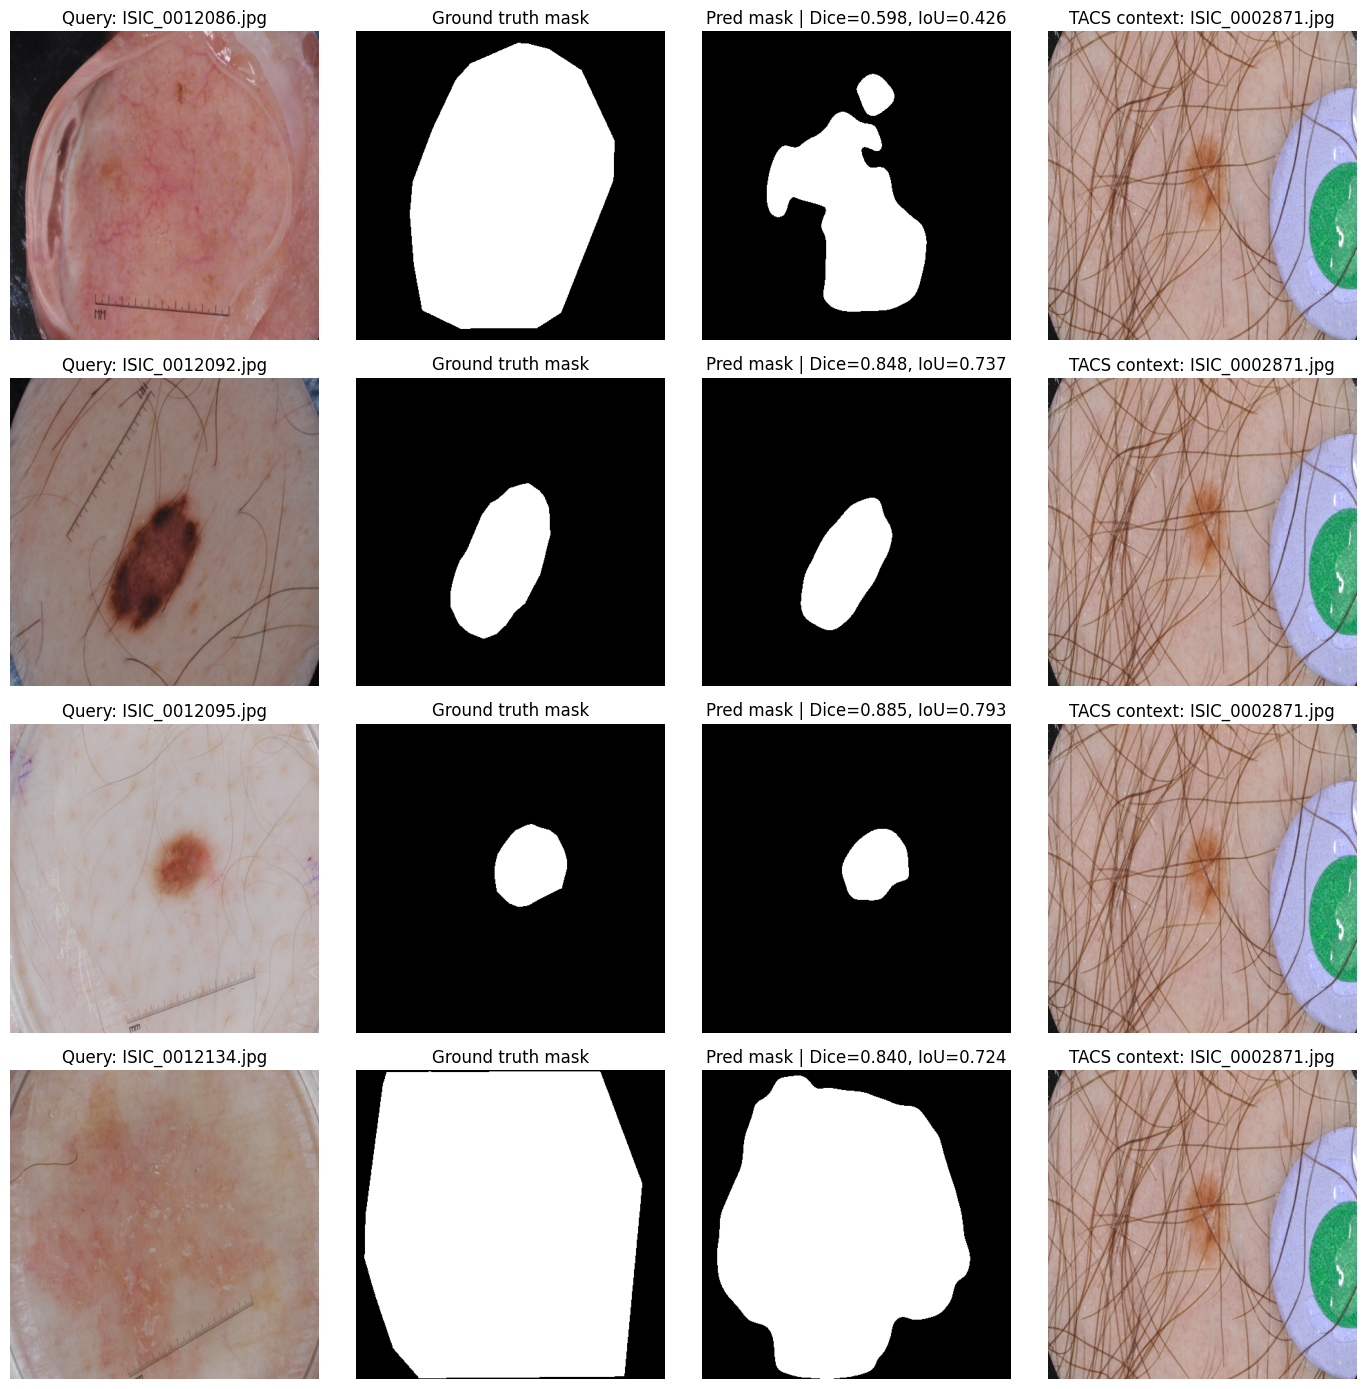

Saved visualization: /kaggle/working/outputs/tacs_isic2017_segmentation/tacs_segmentation_examples.png


In [11]:
def denormalize_image(tensor):
    mean = torch.tensor(IMAGENET_MEAN, device=tensor.device).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD, device=tensor.device).view(3, 1, 1)
    return (tensor * std + mean).clamp(0, 1)


@torch.no_grad()
def visualize_predictions(num_samples=4):
    model.eval()
    batch = next(iter(test_loader))
    moved = move_batch_to_device(batch)
    with torch.amp.autocast("cuda", enabled=DEVICE.type == "cuda"):
        query_tokens, query_global = model.encode_images(moved["images"])
        details = model.select_context(query_global, candidate_global_bank, use_gumbel=False)
        context_tokens = gather_candidate_tokens(details["selected_indices"])
        logits = model.decode_with_context_tokens(query_tokens, context_tokens)
    probs = torch.sigmoid(logits).detach().cpu()
    images = moved["images"].detach().cpu()
    masks = moved["masks"].detach().cpu()
    selected_indices = details["selected_indices"].detach().cpu().tolist()

    n = min(num_samples, images.size(0))
    fig, axes = plt.subplots(n, 4, figsize=(14, 3.5 * n))
    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n):
        query_img = denormalize_image(images[i]).permute(1, 2, 0).numpy()
        gt_mask = masks[i, 0].numpy()
        pred_mask = (probs[i, 0].numpy() > THRESHOLD).astype(np.float32)

        context_row = candidate_df.iloc[selected_indices[i]]
        context_img = Image.open(context_row["image_path"]).convert("RGB")
        context_img = context_img.resize((IMAGE_SIZE, IMAGE_SIZE))

        dice_i, iou_i = dice_iou_from_logits(logits[i:i+1].float(), moved["masks"][i:i+1], threshold=THRESHOLD)

        axes[i, 0].imshow(query_img)
        axes[i, 0].set_title(f"Query: {batch['fname'][i]}")
        axes[i, 1].imshow(gt_mask, cmap="gray")
        axes[i, 1].set_title("Ground truth mask")
        axes[i, 2].imshow(pred_mask, cmap="gray")
        axes[i, 2].set_title(f"Pred mask | Dice={float(dice_i):.3f}, IoU={float(iou_i):.3f}")
        axes[i, 3].imshow(context_img)
        axes[i, 3].set_title(f"TACS context: {context_row['fname']}")
        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    out_path = OUT_PUT_DIR / "tacs_segmentation_examples.png"
    plt.savefig(out_path, dpi=180, bbox_inches="tight")
    plt.show()
    print("Saved visualization:", out_path.resolve())


visualize_predictions(num_samples=4)

## 12. Ghi chú so sánh với paper

- Paper target cho ISIC 2017 segmentation: Dice `85.0`, IoU `76.5`.
- Notebook này dùng đúng các ý TACS cốt lõi: candidate pool 20%, selector học, Gumbel-Softmax, policy reward, standard train/val/test split, và loại chính query khỏi candidate scores trong training nếu query nằm trong pool.
- Khác biệt lớn nhất: paper chèn gated cross-attention vào từng transformer block và dùng DPT head; notebook dùng gated cross-attention trên final patch tokens và DPT-lite head để triển khai gọn, dễ debug.
- Kết quả nên được xem là reproduction/approximation thực nghiệm. Muốn fidelity cao hơn nữa thì bước tiếp theo là can thiệp trực tiếp vào từng ViT block của DINOv3.